# TrOCR Hindi OCR: Ablation Study

This notebook turns your **TrOCR_HI baseline** (DeiT-base image encoder + multilingual-BERT text decoder, trained on the 80k Hindi synthetic line-image dataset) into a controlled **ablation study**.

**Idea:** train the baseline once, then change **exactly one thing at a time** and measure how CER / WER move. Whatever gets worse when a component is removed or replaced tells you how much that component was contributing.

### Before you run
1. Settings → Accelerator: **GPU (T4 or P100)**, Internet: **On** (needed to download the pretrained weights and the CER/WER metrics).
2. Add Data → attach **"Hindi OCR synthetic line image-text pair"** (prathmeshzade).
3. First set `RUN_ONLY = ["baseline"]` in the config cell and run once, to find out how long one run takes on your GPU. Then widen it.

### Experiments

| Group | Variant | Change vs. baseline | Question it answers |
|---|---|---|---|
| reference | `baseline` | nothing | the number everything is compared to |
| augmentation | `no_aug` | ElasticTransform and GaussianBlur both removed | do augmentations help at all? |
| augmentation | `elastic_only` | GaussianBlur removed | what does ElasticTransform add? |
| augmentation | `blur_only` | ElasticTransform removed | what does GaussianBlur add? |
| preprocessing | `resize_pad` | keep aspect ratio and pad to 384x384 instead of squashing | does squashing wide line images hurt? |
| initialization | `freeze_encoder` | DeiT encoder frozen, only decoder and cross-attention train | must the vision encoder be fine-tuned? |
| initialization | `random_encoder` | DeiT encoder randomly initialised | value of ImageNet pretraining |
| initialization | `random_decoder` | BERT decoder randomly initialised | value of multilingual-BERT pretraining |
| data | `data_50pct`, `data_25pct` | half / quarter of the training subset, same epochs | how data-hungry is the model? |
| optimization | `lr_1e-4`, `lr_1e-5` | learning rate (baseline 4e-5) | sensitivity to learning rate |
| decoding (no retraining) | `greedy`, `beam4_no_ngram_block`, `beam4_lp1.0`, `beam8` | generation settings used on the trained baseline | does beam search / trigram blocking / length penalty matter? |

### What differs from your baseline notebook (and why)
- All settings live in one **config cell**; each ablation is a small override of it.
- The held-out 10% is split into **validation** and **test**. The baseline used one set for both.
- Training uses a **reduced budget** (subset + 2 epochs) so a dozen runs fit in Kaggle's weekly GPU quota. The baseline is re-run under this same budget, so the comparison stays fair.
- No wandb, no mid-training evaluation, no checkpoints (saves time and disk). Evaluation happens once at the end of each run.
- Forced to **one GPU** so the effective batch size is 8 in every run (T4 x2 would silently double it).
- `transformers` is pinned so the code behaves the same regardless of Kaggle's image.
- The `reset_index` call was moved out of `__getitem__` (it ran on every sample).
- Everything else is unchanged: same model, transforms, learning rate, batch size, fp16, special tokens and beam-search settings.

## 1. Install dependencies

Installs the Hugging Face libraries plus `evaluate` and `jiwer`, which compute CER and WER. `transformers` is pinned to a version that supports the training arguments used below. `wandb` and `datasets` from the baseline are no longer needed.

If you see a message asking to restart the kernel, restart and run from the top.

In [1]:
!pip install -q evaluate jiwer

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 55.4 MB/s eta 0:00:00


## 2. Imports and environment

Imports everything once. Three environment variables are set *before* torch is imported:
- `CUDA_VISIBLE_DEVICES=0` makes training use a single GPU, so every run has the same effective batch size.
- `WANDB_DISABLED` stops the Trainer from trying to log to Weights & Biases.
- `TOKENIZERS_PARALLELISM=false` avoids tokenizer warnings when the DataLoader uses worker processes.

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["WANDB_DISABLED"] = "true"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

import sys, gc, json, time
import transformers
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
from torchvision.transforms.functional import InterpolationMode
from transformers import (BertTokenizer, VisionEncoderDecoderModel, Seq2SeqTrainer,
                          Seq2SeqTrainingArguments, default_data_collator, set_seed)
from evaluate import load as load_metric

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| transformers", transformers.__version__)
print("Using device:", device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))

Python 3.13.15 | torch 2.11.0+cu128 | transformers 5.16.1
Using device: cuda
Tesla T4


## 3. Configuration (the only cell you normally edit)

- **Paths** point to the dataset and to `/kaggle/working`, where results are saved.
- **Budget knobs** control cost: `N_TRAIN` training images, `EPOCHS`, how many images are used for validation and test, and `SEEDS`. Using several seeds (for example `[42, 43, 44]`) lets you report mean ± std, which you need before claiming a small difference is real.
- **`BASE`** is the baseline recipe. **`VARIANTS`** lists each ablation as a *small override* of `BASE`, which is how one-factor-at-a-time is enforced.
- **`BASE_GEN`** holds the beam-search settings from your baseline, and **`DECODE_VARIANTS`** overrides them for the no-retraining decoding ablation.
- **`RUN_ONLY`** lets you run a subset (start with `["baseline"]`). **`TIME_BUDGET_HOURS`** stops cleanly before Kaggle's session limit. Results are saved after every run, so you can resume.
- **`PREV_RESULTS`**: if a session ended, save the output as a dataset, attach it, and point this at its `ablation_results.json`. Finished runs are then skipped.

In [3]:
# ---------- paths ----------
DATA_ROOT   = "/kaggle/input/hindi-ocr-synthetic-line-image-text-pair/data_80k/"
CSV_PATH    = DATA_ROOT + "data.csv"
IMG_DIR     = DATA_ROOT + "output_images/"
OUT_DIR     = "/kaggle/working"
RESULTS_PATH = f"{OUT_DIR}/ablation_results.json"
DECODE_PATH  = f"{OUT_DIR}/decode_results.json"
PREV_RESULTS = None   # e.g. "/kaggle/input/my-previous-output/ablation_results.json"

# ---------- budget knobs ----------
N_TRAIN, N_VAL, N_TEST = 12000, 1000, 2000   # images per split
EPOCHS      = 2
BATCH       = 8          # same as baseline
EVAL_BATCH  = 32
SEEDS       = [42]       # e.g. [42, 43, 44] for mean +- std
TIME_BUDGET_HOURS = 8.0  # stop starting new runs after this
RUN_ONLY    = None       # e.g. ["baseline"] to test timing first; None = everything
SAVE_BASELINE_MODEL = True   # needed for the decoding ablation

# ---------- model (same as baseline) ----------
ENCODER_NAME = "facebook/deit-base-distilled-patch16-384"
DECODER_NAME = "bert-base-multilingual-cased"
IMG_SIZE, MAX_LEN = 384, 64

# ---------- baseline recipe ----------
BASE = dict(
    aug_elastic=True,          # ElasticTransform(alpha=8, sigma=5)
    aug_blur=True,             # GaussianBlur(kernel (5,9), sigma (0.1,5))
    resize_mode="squash",      # "squash" = Resize((384,384)) as in baseline, "pad" = keep aspect ratio
    freeze_encoder=False,
    pretrained_encoder=True,
    pretrained_decoder=True,
    lr=4e-5,
    n_train=N_TRAIN,
)

# ---------- training ablations: each is ONE change to BASE ----------
VARIANTS = {
    "baseline":       {},
    "no_aug":         dict(aug_elastic=False, aug_blur=False),
    "elastic_only":   dict(aug_blur=False),
    "blur_only":      dict(aug_elastic=False),
    "resize_pad":     dict(resize_mode="pad"),
    "freeze_encoder": dict(freeze_encoder=True),
    "random_encoder": dict(pretrained_encoder=False),
    "random_decoder": dict(pretrained_decoder=False),
    "data_50pct":     dict(n_train=N_TRAIN // 2),
    "data_25pct":     dict(n_train=N_TRAIN // 4),
    "lr_1e-4":        dict(lr=1e-4),
    "lr_1e-5":        dict(lr=1e-5),
}
GROUP = {
    "baseline": "reference",
    "no_aug": "augmentation", "elastic_only": "augmentation", "blur_only": "augmentation",
    "resize_pad": "preprocessing",
    "freeze_encoder": "initialization", "random_encoder": "initialization", "random_decoder": "initialization",
    "data_50pct": "data", "data_25pct": "data",
    "lr_1e-4": "optimization", "lr_1e-5": "optimization",
}

# ---------- decoding (same as baseline) and its ablations (no retraining) ----------
BASE_GEN = dict(num_beams=4, no_repeat_ngram_size=3, length_penalty=2.0,
                early_stopping=True, max_length=MAX_LEN)
DECODE_VARIANTS = {
    "baseline_decode":      {},
    "greedy":               dict(num_beams=1, early_stopping=False, length_penalty=1.0),
    "beam4_no_ngram_block": dict(no_repeat_ngram_size=0),
    "beam4_lp1.0":          dict(length_penalty=1.0),
    "beam8":                dict(num_beams=8),
}
print(f"{len(VARIANTS)} training variants x {len(SEEDS)} seed(s); {len(DECODE_VARIANTS)} decoding variants")

12 training variants x 1 seed(s); 5 decoding variants


## 4. Load the data and build the splits

Reads `data.csv` (columns `image_file` and `text`) and keeps your baseline's split: the first 90% is the training pool and the last 10% is held out. The held-out part is then cut in half:
- **validation**: used to compare variants and make decisions
- **test**: reported once per variant in the final table

Training images are sampled once with a fixed `random_state`, so **every variant sees exactly the same data**. The `data_50pct` / `data_25pct` variants take the first half / quarter of that same sample, so the subsets are nested.

In [4]:
import glob
_hits = [p for p in glob.glob("/kaggle/input/**/data.csv", recursive=True) if "data_80k" in p]
print("found:", _hits)
assert _hits, "data.csv not found"
DATA_ROOT = os.path.dirname(_hits[0]) + "/"
CSV_PATH  = DATA_ROOT + "data.csv"
IMG_DIR   = DATA_ROOT + "output_images/"
print("DATA_ROOT =", DATA_ROOT)

df = pd.read_csv(CSV_PATH)
cut = int(len(df) * 0.9)
train_pool, heldout = df[:cut], df[cut:]
half = len(heldout) // 2
val_pool, test_pool = heldout.iloc[:half], heldout.iloc[half:]

base_sub = train_pool.sample(n=min(N_TRAIN, len(train_pool)), random_state=0).reset_index(drop=True)
val_df   = val_pool.sample(n=min(N_VAL, len(val_pool)), random_state=0).reset_index(drop=True)
test_df  = test_pool.sample(n=min(N_TEST, len(test_pool)), random_state=0).reset_index(drop=True)

print(f"full: {len(df)} | train subset: {len(base_sub)} | val: {len(val_df)} | test: {len(test_df)}")
df.head()

found: ['/kaggle/input/datasets/prathmeshzade/hindi-ocr-synthetic-line-image-text-pair/data_80k/data.csv']
DATA_ROOT = /kaggle/input/datasets/prathmeshzade/hindi-ocr-synthetic-line-image-text-pair/data_80k/
full: 80000 | train subset: 12000 | val: 1000 | test: 2000


,image_file,text,font_size,font_file,word_count
0,1.png,गर्भनिरोध के लिए महिलाएं क्यों कराती हैं नसबंदी,51,Lohit-Devanagari.ttf,8
1,2.png,'मस्‍ज‍िद ख़ुदा का घर है तो यह ईमान वाली स्‍त्...,31,Lohit-Devanagari.ttf,17
2,3.png,"नज़रिया: गोरखपुर, नागपुर और दिल्ली के त्रिकोण ...",39,Sura-Regular.ttf,11
3,4.png,अनुच्छेद 370 के बाद क्या हो सकता है मोदी सरकार...,35,arial-unicode-ms.ttf,13
4,5.png,इराक़ में तीन अमरीकी सैनिक मारे गए,58,NotoSansDevanagari.ttf,7


## 5. Tokenizer, metrics, and a tokenizer sanity check

Loads the multilingual-BERT tokenizer (the decoder's vocabulary) and the CER / WER metrics.

Then a **round-trip test**: encode real Hindi text, decode it back, and measure the CER between the original and the result. Any error here is a floor that no model can beat, caused purely by how this tokenizer handles Devanagari (unknown tokens, spacing around punctuation). It also counts how many lines are longer than `MAX_LEN` tokens and therefore get truncated. If this floor is not close to 0, it is a finding worth reporting in itself.

Note: like your baseline, the evaluation compares predictions against the **decoded label tokens**, not the raw text, so this floor is not included in the model CERs reported below.

In [5]:
tokenizer = BertTokenizer.from_pretrained(DECODER_NAME)
cer_metric = load_metric("cer")
wer_metric = load_metric("wer")

sample = df["text"].sample(2000, random_state=0).tolist()
roundtrip = [tokenizer.decode(tokenizer(t, truncation=True, max_length=MAX_LEN).input_ids,
                              skip_special_tokens=True) for t in sample]
n_trunc = sum(len(tokenizer(t).input_ids) > MAX_LEN for t in sample)
n_unk = sum(tokenizer.unk_token_id in tokenizer(t).input_ids for t in sample)
pairs = [(p, r) for p, r in zip(roundtrip, sample) if r.strip()]
rt_cer = cer_metric.compute(predictions=[p for p, _ in pairs], references=[r for _, r in pairs])

print(f"tokenizer round-trip CER (floor): {rt_cer*100:.2f}%")
print(f"lines truncated at {MAX_LEN} tokens: {n_trunc}/{len(sample)}")
print(f"lines containing [UNK]: {n_unk}/{len(sample)}")
for t, r in list(zip(sample, roundtrip))[:3]:
    print("orig :", t); print("trip :", r); print()

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

tokenizer round-trip CER (floor): 1.62%
lines truncated at 64 tokens: 0/2000
lines containing [UNK]: 12/2000
orig : लॉकडाउन में क्या कर रही हैं आयुष्मान भारत की पहली लाभार्थी करिश्मा
trip : लॉकडाउन में क्या कर रही हैं आयुष्मान भारत की पहली लाभार्थी करिश्मा

orig : ना बंटी, ना बबली, केवल बिग बी
trip : ना बंटी, ना बबली, केवल बिग बी

orig : किशोरों में बढ़ती ई-सिगरेट की लत
trip : किशोरों में बढ़ती ई - सिगरेट की लत



## 6. Image transforms (where the augmentation and preprocessing ablations live)

`build_transform(cfg, train)` assembles the image pipeline from the config flags:
- training: optional **ElasticTransform** and **GaussianBlur** (exactly the baseline's parameters), then resize, tensor conversion and normalisation
- evaluation: never augmented, only resize + normalise

`resize_mode` selects how the line image becomes 384x384:
- `"squash"`: plain `Resize((384,384))` as in your baseline. A wide, short line gets stretched to a square, which distorts the glyphs.
- `"pad"`: `ResizePad` scales the image to fit inside 384x384 **keeping its aspect ratio** and fills the rest with the image's own background colour (taken from its top-left pixel). Text will be smaller, so this variant tests whether squashing is hurting or helping.

The evaluation transform always uses the same `resize_mode` as training, since the model must see the same kind of input at test time.

In [6]:
class ResizePad:
    """Fit image inside size x size keeping aspect ratio; pad with its background colour."""
    def __init__(self, size=IMG_SIZE):
        self.size = size
    def __call__(self, img):
        w, h = img.size
        s = min(self.size / w, self.size / h)
        nw, nh = max(1, round(w * s)), max(1, round(h * s))
        fill = img.getpixel((0, 0))
        canvas = Image.new("RGB", (self.size, self.size), fill)
        canvas.paste(img.resize((nw, nh), Image.BILINEAR), ((self.size - nw) // 2, (self.size - nh) // 2))
        return canvas

def build_transform(cfg, train):
    ops = []
    if train and cfg["aug_elastic"]:
        ops.append(v2.ElasticTransform(alpha=8.0, sigma=5.0, interpolation=InterpolationMode.BILINEAR, fill=0))
    if train and cfg["aug_blur"]:
        ops.append(v2.GaussianBlur(kernel_size=(5, 9), sigma=(0.1, 5.)))
    ops.append(ResizePad(IMG_SIZE) if cfg["resize_mode"] == "pad" else v2.Resize((IMG_SIZE, IMG_SIZE)))
    ops += [v2.ToTensor(), v2.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])]
    return v2.Compose(ops)

### Preview the transforms

Before spending GPU time, look at what the model will actually see for one image under four settings. Check that the augmentation is not destroying the text and that the padded version is still readable.

/usr/local/lib/python3.13/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


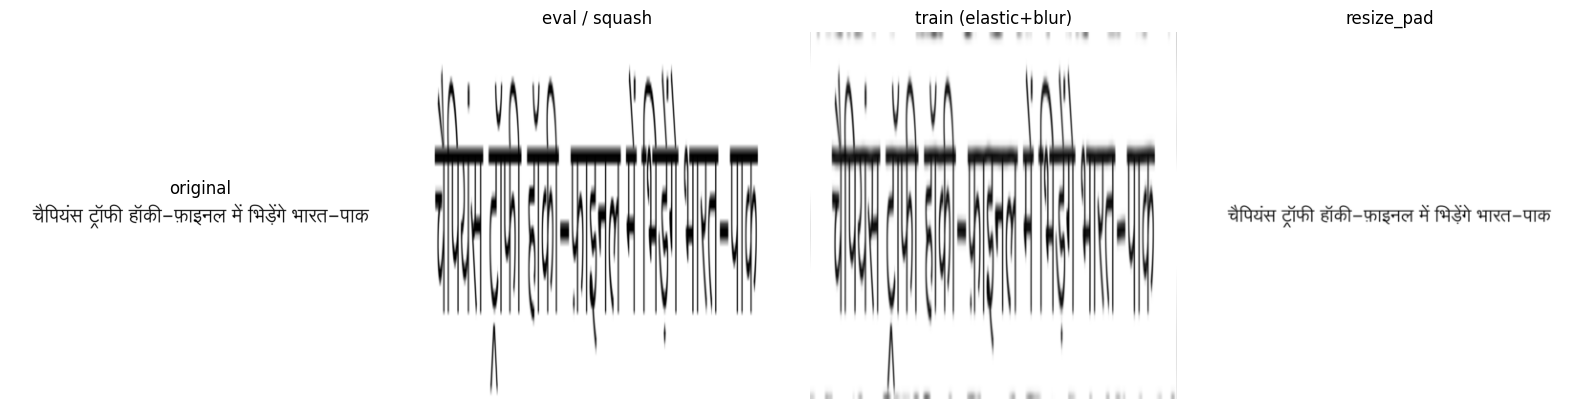

original size: (900, 64)


In [7]:
img = Image.open(IMG_DIR + base_sub["image_file"][0]).convert("RGB")
panels = {
    "original": None,
    "eval / squash": build_transform(BASE, train=False),
    "train (elastic+blur)": build_transform(BASE, train=True),
    "resize_pad": build_transform({**BASE, "resize_mode": "pad"}, train=False),
}
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (title, tf) in zip(axes, panels.items()):
    if tf is None:
        ax.imshow(img)
    else:
        ax.imshow((tf(img) * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
print("original size:", img.size)

## 7. Dataset class

Same as your baseline: for each row it opens the image, applies the transform, and tokenizes the text into `labels` padded to `MAX_LEN`. Padding positions are set to `-100` so the loss ignores them. Only change: the file names and texts are pulled into plain lists once in `__init__` instead of calling `reset_index` on every sample.

In [8]:
class OCRdataset(Dataset):
    def __init__(self, root_dir, df, tokenizer, max_target_length=MAX_LEN, transforms=None):
        self.root_dir = root_dir
        self.files = df["image_file"].tolist()
        self.texts = df["text"].tolist()
        self.tokenizer = tokenizer
        self.max_target_length = max_target_length
        self.transforms = transforms

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        image = Image.open(self.root_dir + self.files[idx]).convert("RGB")
        pixel_values = self.transforms(image)
        labels = self.tokenizer(self.texts[idx], padding="max_length", truncation=True,
                                max_length=self.max_target_length).input_ids
        labels = [l if l != self.tokenizer.pad_token_id else -100 for l in labels]
        return {"pixel_values": pixel_values, "labels": torch.tensor(labels)}

## 8. Model builder (where the initialization ablations live)

`build_model(cfg)` creates the same model as your baseline: a DeiT-base encoder and a multilingual-BERT decoder joined with freshly initialised cross-attention layers. Then, depending on the config:
- `pretrained_encoder=False` / `pretrained_decoder=False`: re-initialises that part's weights randomly, discarding its pretraining.
- `freeze_encoder=True`: turns off gradients for the encoder so only the decoder and cross-attention are trained.

Afterwards it sets the special tokens and the vocabulary size exactly as in the baseline (start token = `[CLS]`, end token = `[SEP]`, etc.).

In [9]:
def reinit(module):
    """Throw away pretrained weights by re-running the model's own random initialisation."""
    module.apply(module._init_weights)

def build_model(cfg):
    model = VisionEncoderDecoderModel.from_encoder_decoder_pretrained(ENCODER_NAME, DECODER_NAME)
    if not cfg["pretrained_encoder"]:
        reinit(model.encoder)
    if not cfg["pretrained_decoder"]:
        reinit(model.decoder)
    if cfg["freeze_encoder"]:
        for p in model.encoder.parameters():
            p.requires_grad = False

        # special tokens, same values as the baseline notebook
    model.config.decoder_start_token_id = tokenizer.cls_token_id
    model.config.pad_token_id = tokenizer.pad_token_id
    model.config.vocab_size = model.config.decoder.vocab_size
    model.config.eos_token_id = tokenizer.sep_token_id

    # beam-search settings, same values as the baseline
    g = model.generation_config
    g.decoder_start_token_id = tokenizer.cls_token_id
    g.pad_token_id = tokenizer.pad_token_id
    g.eos_token_id = tokenizer.sep_token_id
    g.max_length = MAX_LEN
    g.early_stopping = True
    g.no_repeat_ngram_size = 3
    g.length_penalty = 2.0
    g.num_beams = 4
    return model

## 9. Prediction and scoring

- `make_gen_kwargs` builds the generation settings (beam search etc.) and adds the special-token ids explicitly, so decoding does not depend on what is stored in the model config.
- `predict` runs the model over a dataframe in batches and returns the predicted strings plus the reference strings. The references are the decoded label tokens, as in your baseline's `compute_metrics`.
- `score` computes **CER** and **WER**. Empty references are skipped, since the metric cannot handle them.

In [10]:
def make_gen_kwargs(overrides=None):
    g = dict(BASE_GEN)
    if overrides:
        g.update(overrides)
    g.update(decoder_start_token_id=tokenizer.cls_token_id,
             pad_token_id=tokenizer.pad_token_id,
             eos_token_id=tokenizer.sep_token_id)
    return g

@torch.no_grad()
def predict(model, df, transform, gen_overrides=None, batch_size=EVAL_BATCH):
    ds = OCRdataset(IMG_DIR, df, tokenizer, transforms=transform)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=2)
    kw = make_gen_kwargs(gen_overrides)
    model.eval()
    preds, refs = [], []
    for batch in loader:
        pixel_values = batch["pixel_values"].to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device.type == "cuda")):
            ids = model.generate(pixel_values, **kw)
        preds += tokenizer.batch_decode(ids, skip_special_tokens=True)
        labels = batch["labels"].clone()
        labels[labels == -100] = tokenizer.pad_token_id
        refs += tokenizer.batch_decode(labels, skip_special_tokens=True)
    return preds, refs

def score(preds, refs):
    pairs = [(p, r) for p, r in zip(preds, refs) if len(r.strip()) > 0]
    P, R = [p for p, _ in pairs], [r for _, r in pairs]
    cer = cer_metric.compute(predictions=P, references=R)
    wer = wer_metric.compute(predictions=P, references=R)
    return 100 * cer, 100 * wer     # in percent

## 10. One experiment = one function

`run_one(name, change, seed)` is the heart of the study. It:
1. merges the variant's override into `BASE` to get that run's config,
2. fixes the random seed,
3. builds the dataset (with that variant's transforms) and the model,
4. trains with the baseline's hyper-parameters (batch size 8, fp16, linear LR decay), changing only what the config says,
5. evaluates on validation and test with the baseline decoding settings,
6. returns a result record (CER, WER, final training loss, trainable parameters, minutes),
7. frees GPU memory so the next run starts clean.

The trained baseline (first seed only) is saved to disk so section 12 can test decoding settings without retraining.

In [11]:
def run_one(name, change, seed):
    cfg = {**BASE, **change}
    set_seed(seed)

    train_ds = OCRdataset(IMG_DIR, base_sub.iloc[:cfg["n_train"]], tokenizer,
                          transforms=build_transform(cfg, train=True))
    model = build_model(cfg)
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

    args = Seq2SeqTrainingArguments(
        output_dir=f"{OUT_DIR}/tmp_run",
        per_device_train_batch_size=BATCH,
        num_train_epochs=EPOCHS,
        learning_rate=cfg["lr"],
        fp16=(device.type == "cuda"),
        eval_strategy="no", save_strategy="no",
        logging_steps=100, disable_tqdm=True, report_to="none",
        seed=seed, data_seed=seed, dataloader_num_workers=2,
    )
    trainer_kwargs = dict(model=model, args=args, train_dataset=train_ds,
                          data_collator=default_data_collator)
    try:   # newer transformers
        trainer = Seq2SeqTrainer(processing_class=tokenizer, **trainer_kwargs)
    except TypeError:   # older transformers
        trainer = Seq2SeqTrainer(tokenizer=tokenizer, **trainer_kwargs)

    t0 = time.time()
    out = trainer.train()
    train_min = (time.time() - t0) / 60

    eval_tf = build_transform(cfg, train=False)
    val_cer, val_wer = score(*predict(model, val_df, eval_tf))
    test_cer, test_wer = score(*predict(model, test_df, eval_tf))

    if name == "baseline" and seed == SEEDS[0] and SAVE_BASELINE_MODEL:
        trainer.save_model(f"{OUT_DIR}/baseline_model")

    rec = dict(variant=name, seed=seed, change=json.dumps(change),
               val_cer=val_cer, val_wer=val_wer, test_cer=test_cer, test_wer=test_wer,
               train_loss=out.training_loss, trainable_params=n_trainable, train_min=train_min)

    del trainer, model, train_ds
    gc.collect(); torch.cuda.empty_cache()
    return rec

## 11. Run the ablations

Loops over seeds and variants (baseline first). For each pair it skips anything already finished, checks that there is still time left in the budget, runs the experiment, prints the result, and **writes `ablation_results.json` immediately**. If Kaggle stops the session or a run crashes, only that run is lost. Re-run this cell (with `PREV_RESULTS` set if the session restarted) and it continues where it left off.

Tip: run this as **Save & Run All (Commit)** so it keeps going after you close the browser.

In [12]:
def load_records():
    recs = []
    for path in (PREV_RESULTS, RESULTS_PATH):
        if path and os.path.exists(path):
            recs += json.load(open(path))
    uniq = {(r["variant"], r["seed"]): r for r in recs}
    return list(uniq.values())

records = load_records()
done = {(r["variant"], r["seed"]) for r in records}
queue = [(s, n) for s in SEEDS for n in VARIANTS if (RUN_ONLY is None or n in RUN_ONLY) and (n, s) not in done]
print(f"{len(done)} already done, {len(queue)} to run")

t_start, last_hours = time.time(), 0.0
for seed, name in queue:
    elapsed = (time.time() - t_start) / 3600
    if elapsed + last_hours > TIME_BUDGET_HOURS:
        print(f"Time budget reached ({elapsed:.1f} h). Re-run this cell later to continue.")
        break
    t0 = time.time()
    print(f"\n=== {name} | seed {seed} | {VARIANTS[name]} ===")
    try:
        rec = run_one(name, VARIANTS[name], seed)
    except Exception as e:
        print(f"!! {name} failed: {type(e).__name__}: {e}")
        gc.collect(); torch.cuda.empty_cache()
        continue
    records.append(rec)
    json.dump(records, open(RESULTS_PATH, "w"), indent=1)
    last_hours = (time.time() - t0) / 3600
    print(f"val CER {rec['val_cer']:.2f}% | test CER {rec['test_cer']:.2f}% | test WER {rec['test_wer']:.2f}% | {rec['train_min']:.1f} min train")

0 already done, 12 to run

=== baseline | seed 42 | {} ===


config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  351MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] DeiTModel LOAD REPORT from: facebook/deit-base-distilled-patch16-384
Key                            | Status     | 
-------------------------------+------------+-
distillation_classifier.weight | UNEXPECTED | 
cls_classifier.weight          | UNEXPECTED | 
cls_classifier.bias            | UNEXPECTED | 
distillation_classifier.bias   | UNEXPECTED | 
pooler.dense.weight            | MISSING    | 
pooler.dense.bias              | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (82 outputs left out)

[transformers] BertLMHeadModel LOAD REPORT from: bert-base-multilingual-cased
Key                                                                | Status     | 
-------------------------------------------------------------------+------------+-
cls.seq_relationship.weight                                        | UNEXPECTED | 
bert.pooler.dense.bias                                             | UNEXPECTED | 
cls.seq_relationship.bias                                          | UNEXPECTED | 
bert.pooler.dense.weight                                           | UNEXPECTED | 
bert.encoder.layer.{0...11}.crossattention.output.dense.bias       | MISSING    | 
bert.encoder.layer.{0...11}.crossattention.self.query.bias         | MISSING    | 
bert.encoder.layer.{0...11}.crossattention.self.query.weight       | MISSING    | 
bert.encoder.layer.{0...11}.crossattention.self.value.weight       | MISSING    | 
bert.encoder.layer.{0...11}.crossattention.output.dense.weight     | MISSING    | 
bert.enco

{'loss': '6.428', 'grad_norm': '15.88', 'learning_rate': '9.67e-06', 'epoch': '0.06667'}
{'loss': '4.867', 'grad_norm': '15.38', 'learning_rate': '9.337e-06', 'epoch': '0.1333'}
{'loss': '4.518', 'grad_norm': '15.89', 'learning_rate': '9.003e-06', 'epoch': '0.2'}
{'loss': '4.331', 'grad_norm': '15.07', 'learning_rate': '8.67e-06', 'epoch': '0.2667'}
{'loss': '4.177', 'grad_norm': '16.14', 'learning_rate': '8.337e-06', 'epoch': '0.3333'}
{'loss': '4.125', 'grad_norm': '14.37', 'learning_rate': '8.003e-06', 'epoch': '0.4'}
{'loss': '3.954', 'grad_norm': '13.76', 'learning_rate': '7.67e-06', 'epoch': '0.4667'}
{'loss': '3.911', 'grad_norm': '15.65', 'learning_rate': '7.337e-06', 'epoch': '0.5333'}
{'loss': '3.827', 'grad_norm': '13.3', 'learning_rate': '7.003e-06', 'epoch': '0.6'}
{'loss': '3.771', 'grad_norm': '14.68', 'learning_rate': '6.67e-06', 'epoch': '0.6667'}
{'loss': '3.735', 'grad_norm': '12.12', 'learning_rate': '6.337e-06', 'epoch': '0.7333'}
{'loss': '3.662', 'grad_norm': '14

/usr/local/lib/python3.13/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


val CER 79.34% | test CER 79.47% | test WER 95.06% | 19.8 min train


## 12. Decoding ablation (no retraining)

Beam search, trigram blocking (`no_repeat_ngram_size=3`) and the length penalty are *inference-time* choices, so they can be ablated on the **already trained baseline** without any new training. That makes this the cheapest part of the study.

`no_repeat_ngram_size=3` is worth special attention for OCR: it forbids repeating any 3-token sequence, but real text (and repeated characters or words) can legitimately repeat, so it can silently force errors.

In [13]:
decode_records = []
model_path = f"{OUT_DIR}/baseline_model"
if not os.path.exists(model_path):
    print("Baseline model not found: run the 'baseline' variant in section 11 first.")
else:
    model = VisionEncoderDecoderModel.from_pretrained(model_path).to(device)
    eval_tf = build_transform(BASE, train=False)
    for name, over in DECODE_VARIANTS.items():
        t0 = time.time()
        v_cer, v_wer = score(*predict(model, val_df, eval_tf, over))
        t_cer, t_wer = score(*predict(model, test_df, eval_tf, over))
        decode_records.append(dict(variant=name, change=json.dumps(over), val_cer=v_cer, val_wer=v_wer,
                                   test_cer=t_cer, test_wer=t_wer, minutes=(time.time() - t0) / 60))
        print(f"{name:22s} val CER {v_cer:.2f}% | test CER {t_cer:.2f}% | test WER {t_wer:.2f}%")
    json.dump(decode_records, open(DECODE_PATH, "w"), indent=1)
    del model; gc.collect(); torch.cuda.empty_cache()

Loading weights:   0%|          | 0/523 [00:00<?, ?it/s]

baseline_decode        val CER 77.91% | test CER 78.37% | test WER 92.04%
greedy                 val CER 76.02% | test CER 76.09% | test WER 92.48%
beam4_no_ngram_block   val CER 78.30% | test CER 78.72% | test WER 91.90%
beam4_lp1.0            val CER 77.36% | test CER 77.92% | test WER 91.72%
beam8                  val CER 78.94% | test CER 78.98% | test WER 91.82%


## 13. Results table

Groups the records by variant. With several seeds it reports the **mean** and the **standard deviation**. `delta_cer` is the variant's test CER minus the baseline's, in percentage points: **positive means the change made it worse** (so the removed component was helping), negative means it improved. The table is also saved as `ablation_summary.csv`.

In [14]:
res = pd.DataFrame(load_records())
agg = res.groupby("variant").agg(
    seeds=("seed", "count"),
    val_cer=("val_cer", "mean"),
    test_cer=("test_cer", "mean"), test_cer_std=("test_cer", "std"),
    test_wer=("test_wer", "mean"),
    trainable_M=("trainable_params", lambda s: s.iloc[0] / 1e6),
    train_min=("train_min", "mean"),
)
agg = agg.reindex([v for v in VARIANTS if v in agg.index])
agg.insert(0, "group", [GROUP[v] for v in agg.index])
if "baseline" in agg.index:
    agg["delta_cer"] = agg["test_cer"] - agg.loc["baseline", "test_cer"]
display(agg.round(2))
agg.round(3).to_csv(f"{OUT_DIR}/ablation_summary.csv")

if os.path.exists(DECODE_PATH):
    print("\nDecoding ablation (same trained baseline, different generation settings):")
    dec = pd.DataFrame(json.load(open(DECODE_PATH))).set_index("variant")
    dec["delta_cer"] = dec["test_cer"] - dec.loc["baseline_decode", "test_cer"]
    display(dec[["val_cer", "test_cer", "test_wer", "delta_cer"]].round(2))
    dec.round(3).to_csv(f"{OUT_DIR}/decode_summary.csv")

,group,seeds,val_cer,test_cer,test_cer_std,test_wer,trainable_M,train_min,delta_cer
variant,,,,,,,,,
baseline,reference,1,77.91,78.37,NaN,92.04,293.02,19.63,0.00
no_aug,augmentation,1,76.15,76.10,NaN,90.06,293.02,19.35,-2.27
elastic_only,augmentation,1,75.10,75.22,NaN,88.65,293.02,19.65,-3.15
blur_only,augmentation,1,79.86,79.21,NaN,93.60,293.02,19.39,0.84
resize_pad,preprocessing,1,80.49,80.95,NaN,92.79,293.02,19.69,2.58
freeze_encoder,initialization,1,79.83,79.74,NaN,95.81,206.34,16.10,1.37
random_encoder,initialization,1,78.45,77.95,NaN,93.55,293.02,19.80,-0.42
random_decoder,initialization,1,81.05,81.28,NaN,95.96,293.02,19.77,2.91
data_50pct,data,1,83.21,83.04,NaN,97.78,293.02,9.91,4.67



Decoding ablation (same trained baseline, different generation settings):


,val_cer,test_cer,test_wer,delta_cer
variant,,,,
baseline_decode,77.91,78.37,92.04,0.00
greedy,76.02,76.09,92.48,-2.28
beam4_no_ngram_block,78.30,78.72,91.90,0.35
beam4_lp1.0,77.36,77.92,91.72,-0.45
beam8,78.94,78.98,91.82,0.61


## 14. Plot

Horizontal bars of `delta_cer` for each training variant. **Red = worse than baseline, green = better.** Error bars (the std over seeds) appear when you ran more than one seed. Bars that are small relative to the error bar should not be interpreted as real effects. Saved as `ablation_delta_cer.png`.

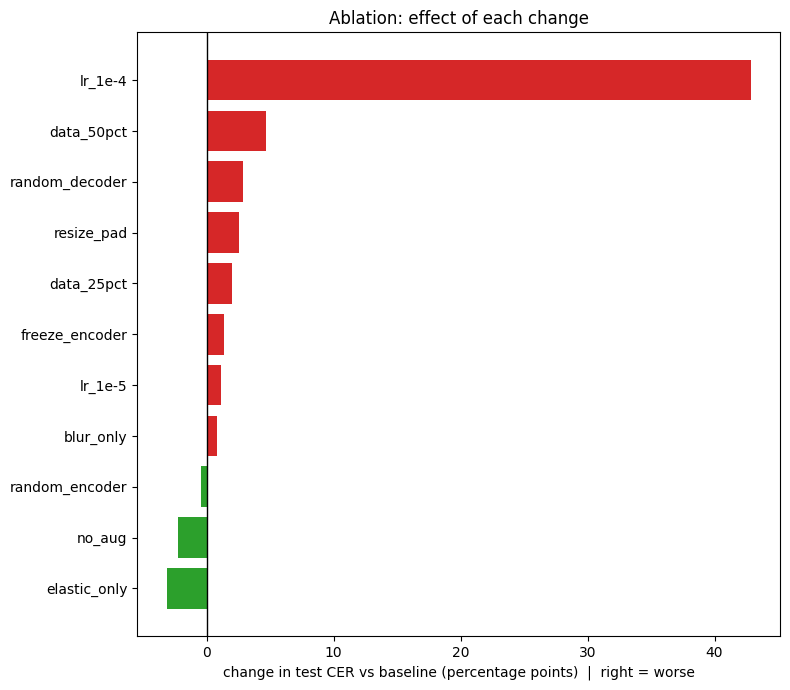

In [15]:
plot_df = agg.drop(index="baseline", errors="ignore")
if "delta_cer" in plot_df and len(plot_df):
    plot_df = plot_df.sort_values("delta_cer")
    colors = ["tab:red" if d > 0 else "tab:green" for d in plot_df["delta_cer"]]
    err = plot_df["test_cer_std"].fillna(0).values
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(plot_df) + 1.5))
    ax.barh(plot_df.index, plot_df["delta_cer"], xerr=err, color=colors)
    ax.axvline(0, color="black", lw=1)
    ax.set_xlabel("change in test CER vs baseline (percentage points)  |  right = worse")
    ax.set_title("Ablation: effect of each change")
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/ablation_delta_cer.png", dpi=150)
    plt.show()
else:
    print("Run the baseline and at least one other variant first.")

## 15. How to read and report the results

- **Compare against `baseline` from this notebook**, not against your earlier full-budget numbers. The budget here is deliberately smaller.
- **Use validation for decisions and test for the table you report.**
- **Single seed warning:** with one seed, differences of a few tenths of a CER point can be noise. If a result matters for your argument, rerun that variant and the baseline with `SEEDS = [42, 43, 44]`.
- For each row, write one sentence on *why* it behaved that way (for example, "removing augmentation hurt most on the blurred lines"). That explanation is what turns a results table into an ablation study.

### Limitations to state in your write-up
- One-factor-at-a-time cannot show **interactions** (for example, augmentation may matter more when the encoder is frozen).
- Reduced training budget: effects may change at the full 7-epoch, 72k-image budget.
- The data is **synthetic**, so conclusions may not transfer to real scanned documents. Evaluate on a small set of real labelled line images if you have one.
- WER depends on whitespace tokenisation of Devanagari; CER is the more reliable headline metric.
- The decoding ablation uses one trained model (first seed).